# 31 · Transfer the MNIST protocol without tuning

Fashion-MNIST shares MNIST's 28 × 28 grayscale format, so the finite-image geometry and all metric settings can be carried over directly. The change is in the images and labels. Exclude every test image used in the earlier Fashion-MNIST smoke and distractor experiments, then draw twelve new galleries.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage8 import BASELINES,FROZEN,VIEWS,contrast
from observables.stage9 import load_fashion,observations,cross_dataset_contrast
from observables.stage6 import CONDITIONS
OUT=ROOT/'results'/'stage9'
MNIST=ROOT/'results'/'stage8'
CATEGORIES=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

Matplotlib is building the font cache; this may take a moment.


## What is fixed
Each gallery has 40 originals, four per category. Exact-source retrieval has one target in 40. Same-category retrieval excludes the source and has three targets in 39. The eight transformation recipes, mask semantics, allowed 49 translation offsets, minimum 65% shared support and tie rule match the fresh MNIST panel. No learning or threshold selection uses Fashion-MNIST. This comparison changes the dataset while holding the protocol fixed.

Verify the published test-file digests and IDX headers, then audit the sampled indices and image content. The saved exclusion file records provenance by prior experiment. Original zero-based test indices identify all images.

Excluded prior test IDs: 3080 · fresh sources: 480 · galleries: 12


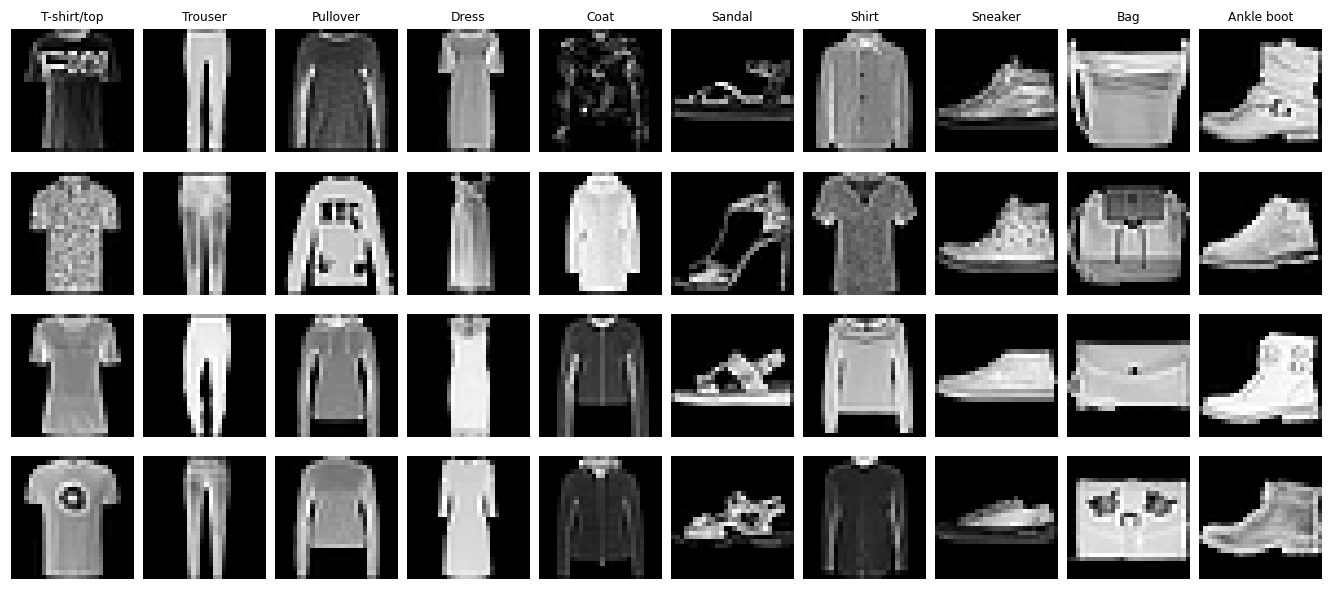

In [3]:
data=load_fashion()
membership=pd.read_csv(OUT/'membership.csv')
excluded=set(pd.read_csv(OUT/'excluded_test_ids.csv').source)
ids=membership.source.to_numpy()
assert len(ids)==len(set(ids))==480
assert set(ids).isdisjoint(excluded)
tokens={data['x_test'][i].tobytes() for i in ids}
assert len(tokens)==480 and tokens.isdisjoint(data['x_test'][i].tobytes() for i in excluded)
assert membership.groupby(['gallery','label']).size().eq(4).all()
print('Excluded prior test IDs:',len(excluded),'· fresh sources:',len(ids),'· galleries:',membership.gallery.nunique())
m=membership[membership.gallery==0].sort_values('label')
fig,axes=plt.subplots(4,10,figsize=(12,5.3))
for col,(label,group) in enumerate(m.groupby('label')):
    for row,i in enumerate(group.source):
        ax=axes[row,col];ax.imshow(data['x_test'][i],cmap='gray',vmin=0,vmax=255)
        ax.set_axis_off()
        if row==0:ax.set_title(CATEGORIES[label],fontsize=8)
show('31_fashion_gallery')

## Check nuisance severity on the original intensity scale
The noise SD is 0.23 for both datasets. The same absolute intensity perturbation can have a different relative strength if the original images have different signal energy. Report clean image RMS across the two selected source panels before interpreting differences between datasets.

In [5]:
from observables.stage6 import load_data
mnist_ids=pd.read_csv(MNIST/'membership.csv').query("panel=='replication'").source
rms=[]
for name,x in [('MNIST',load_data()['x_test'][mnist_ids]),('Fashion-MNIST',data['x_test'][ids])]:
    q=np.sqrt(np.mean((x.astype(float)/255)**2,axis=(1,2)))
    rms.append((name,*np.quantile(q,[.1,.5,.9]),np.median(.23/q)))
display(pd.DataFrame(rms,columns=['dataset','RMS p10','RMS median','RMS p90','median noise SD / RMS']).round(3))

,dataset,RMS p10,RMS median,RMS p90,median noise SD / RMS
0,MNIST,0.262,0.33,0.406,0.697
1,Fashion-MNIST,0.258,0.43,0.614,0.535


## Scope
The two datasets provide a test of transfer across image content and label taxonomies. An observed difference also reflects their sampled sources, effective corruption strengths and how varied the legitimate category matches are. The analysis does not isolate any one of those causes.